<a href="https://colab.research.google.com/github/bensonngi/Python_course_project/blob/main/Tidal_Turbine_Statistical_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
data = pd.read_csv(filename)

print("Dataset imported successfully!")
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])

print("\nColumn names:")
print(data.columns.tolist())

data.head()

Saving synthetic_tidal_turbine_dataset.csv to synthetic_tidal_turbine_dataset.csv
Dataset imported successfully!
Number of rows: 243
Number of columns: 7

Column names:
['Velocity_m_s', 'TSR', 'Rotor_RPM', 'Angular_Velocity_rad_s', 'Torque_Nm', 'Power_W', 'Cp']


,Velocity_m_s,TSR,Rotor_RPM,Angular_Velocity_rad_s,Torque_Nm,Power_W,Cp
0,1.0,1.50,2.86,0.30,2623.07,786.92,0.0200
1,1.0,1.75,3.34,0.35,2848.52,996.98,0.0253
2,1.0,2.00,3.82,0.40,3866.09,1546.43,0.0393
3,1.0,2.25,4.30,0.45,5123.50,2305.57,0.0586
4,1.0,2.50,4.77,0.50,6590.68,3295.34,0.0838


For this problem, four numerical variables were selected from the synthtic data for tidal turbine: flow velocity (v), tip-speed-ratio(TSR), power coefficient (Cp) and mechanical power. This is because the variables are relevant to understanding tidal turbine operating conditions and performance.
The flow velocity and TSR are operating conditions of the turbine, whereas the Cp and mechanical power describe its performance. These variables will be examined using descriptive statistics to understand their distribution and using correlation analysis to investigate the relationships between operating conditions and turbine performance.

In [3]:
selected_variables = [
    "Velocity_m_s",
    "TSR",
    "Cp",
    "Power_W"
]

analysis_data = data[selected_variables]

print("Selected variables:")
print(analysis_data.head())

print("\nData types:")
print(analysis_data.dtypes)

Selected variables:
   Velocity_m_s   TSR      Cp  Power_W
0           1.0  1.50  0.0200   786.92
1           1.0  1.75  0.0253   996.98
2           1.0  2.00  0.0393  1546.43
3           1.0  2.25  0.0586  2305.57
4           1.0  2.50  0.0838  3295.34

Data types:
Velocity_m_s    float64
TSR             float64
Cp              float64
Power_W         float64
dtype: object


Descriptive Statistics

In [4]:
statistics = pd.DataFrame({
    "Mean": analysis_data.mean(),
    "Median": analysis_data.median(),
    "Minimum": analysis_data.min(),
    "Maximum": analysis_data.max(),
    "Range": analysis_data.max() - analysis_data.min(),
    "Variance": analysis_data.var(),
    "Standard Deviation": analysis_data.std()
})

print("Descriptive Statistics")
display(statistics.round(4))

Descriptive Statistics


,Mean,Median,Minimum,Maximum,Range,Variance,Standard Deviation
Velocity_m_s,2.0000,2.0000,1.00,3.0000,2.0000,4.184000e-01,0.6468
TSR,4.7500,4.7500,1.50,8.0000,6.5000,3.807300e+00,1.9512
Cp,0.2292,0.2004,0.02,0.4639,0.4439,2.360000e-02,0.1537
Power_W,94110.2016,47807.7500,786.92,477266.6000,476479.6800,1.221823e+10,110536.0914


Covariance and Correlation Analysis
Covariance and correlation are used to examine the relationship between two numerical variables. Covariance indicates whether the variables tend to increase or decrease together, while correlation measures the strength and direction of their linear relationship.
In this analysis, TSR is the selected input variable and Cp is the output variable

In [5]:
tsr = data["TSR"]
cp = data["Cp"]

covariance = tsr.cov(cp)
correlation = tsr.corr(cp)

print("Covariance between TSR and Cp:", round(covariance, 4))
print("Correlation between TSR and Cp:", round(correlation, 4))

Covariance between TSR and Cp: 0.0518
Correlation between TSR and Cp: 0.1727


A scatter plot to visualize how Cp changes with TSR

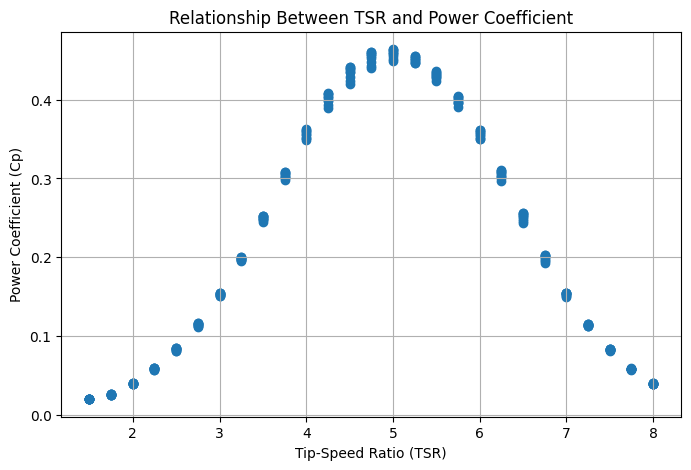

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(data["TSR"], data["Cp"])

plt.xlabel("Tip-Speed Ratio (TSR)")
plt.ylabel("Power Coefficient (Cp)")
plt.title("Relationship Between TSR and Power Coefficient")
plt.grid(True)

plt.show()

Interpretation and Discussion:

The covariance between the tip-speed ratio (TSR) and the power coefficient (Cp) was 0.0518, while the correlation coefficient was 0.1727. The positive covariance indicates that the two variables tend to vary in the same direction overall. However, the correlation coefficient indicates a weak positive linear relationship between TSR and (Cp).

The scatter plot reveals a clearer pattern than the correlation coefficient alone. The power coefficient increases as TSR rises from low values, reaches a maximum of approximately 0.46 at a TSR of around 5, and then decreases as TSR increases further. This produces an approximately inverted U-shaped curve, indicating a nonlinear relationship between the variables.

The weak positive correlation can be explained by the opposing trends on either side of the peak. The initial increase in (Cp) contributes to a positive association, while the subsequent decrease weakens the overall linear correlation. Therefore, a low correlation coefficient does not necessarily mean that two variables are unrelated. It may indicate that their relationship cannot be adequately described by a straight line.

Correlation does not necessarily imply causation. The observed association does not, by itself, prove that changes in TSR cause changes in (Cp). The results reflect the simplified equations and assumptions used to generate the synthetic dataset. Further physical analysis or appropriately designed experiments would be required to establish causal relationships for a real tidal turbine.

Input-Model-Output Relationship:

Input selected: TSR
Function/model: *f*
Output: Predicted power coefficient (Cp)

The mathematical expression is: Cp = *f**(TSR)*

Input: Tip-speed ratio (TSR) -------> Function/Model: *f**(TSR)* -------> Output: Predicted power coefficient (Cp)
      
